## Import Libraries


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import zscore
from sklearn.preprocessing import MinMaxScaler, LabelEncoder, OrdinalEncoder
import warnings
warnings.filterwarnings('ignore')

sns.set(style="whitegrid", palette="Set2", font_scale=1.2)

## Load Dataset & Overview


In [2]:
# Load Dataset
file_path = "Original Dataset of Employee Attrition.xlsx"
df = pd.read_excel(file_path)

# Normalize column names (trim spaces, replace & with _, replace spaces with _)
df.columns = (
    df.columns
      .str.strip()
      .str.replace(r"\s+", " ", regex=True)
      .str.replace("&", "_", regex=False)
      .str.replace(" ", "", regex=False)
      .str.replace(r"_+", "_", regex=True)
      .str.strip("_")
)

print("="*60)
print("DATASET OVERVIEW")
print("="*60)
print(f"Total Rows: {df.shape[0]}")
print(f"Total Columns: {df.shape[1]}")
print(f"\nColumn Names:\n{df.columns.tolist()}")

print("\n" + "="*60)
print("DATA TYPES")
print("="*60)
df.info()

df.head()

DATASET OVERVIEW
Total Rows: 1191
Total Columns: 35

Column Names:
['ID', 'Attrition', 'Gender', 'Age', 'Maritalstatus', 'Academic_degree', 'Years_Experience', 'Years_experience_lastorganization', 'Sector', 'Department', 'JobTitle', 'MonthlySalary', 'Allowances', 'MedicalInsurance', 'Bonus', 'OverTime', 'Payment_Overtime', 'Rewards_Wages_Satisfaction', 'Get_Deserved_Promotion', 'Training_programs_During_last_three_years', 'Useful_Training_Programs', 'Business_Travel', 'Job_Support', 'Recognition', 'Emotional_Commitment', 'Job_Engagement', 'Distance_to_work', 'Work_Live_Balance', 'Physical_Stress', 'Psychological_Exhaustion', 'Job_Stability', 'Health_Issues', 'Environment_Satisfaction', 'Job_Satisfaction', 'Job_Opportunities']

DATA TYPES
<class 'pandas.DataFrame'>
RangeIndex: 1191 entries, 0 to 1190
Data columns (total 35 columns):
 #   Column                                     Non-Null Count  Dtype
---  ------                                     --------------  -----
 0   ID         

,ID,Attrition,Gender,Age,Maritalstatus,Academic_degree,Years_Experience,Years_experience_lastorganization,Sector,Department,...,Job_Engagement,Distance_to_work,Work_Live_Balance,Physical_Stress,Psychological_Exhaustion,Job_Stability,Health_Issues,Environment_Satisfaction,Job_Satisfaction,Job_Opportunities
0,11,Yes,Female,31 to 40,Married,Master's,Less than 5 years,Less than 5 years,Medical sector,Accounting,...,Medium,Medium,Medium,Yes,No,No,Yes,Medium,Not satisfied,Yes
1,12,No,Female,21 to 30,Single,Master's,Less than 5 years,Less than 5 years,Medical sector,Accounting,...,Medium,Medium,Medium,No,No,Yes,No,Medium,Satisfied,No
2,13,No,Female,21 to 30,Single,Bachelor's,Less than 5 years,Less than 5 years,Education sector,Teaching,...,Medium,Close,Medium,Yes,Sometimes,No,No,Medium,Satisfied,Yes
3,14,No,Female,21 to 30,Single,Bachelor's,Less than 5 years,Less than 5 years,Education sector,Teaching,...,Medium,Medium,Medium,Yes,Yes,No,No,Low,Not satisfied,No
4,15,No,Female,21 to 30,Single,Bachelor's,Less than 5 years,Less than 5 years,Education sector,Teaching,...,Medium,Medium,Medium,Sometimes,Sometimes,No,No,Medium,Not satisfied,No


## Missing Values Analysis & Imputation


In [3]:
print("="*60)
print("MISSING VALUES ANALYSIS & IMPUTATION")
print("="*60)

# Check missing values before imputation
missing = df.isna().sum()
missing_pct = (missing / len(df)) * 100
missing_df = pd.DataFrame({'Missing Count': missing, 'Percentage': missing_pct})
missing_before = missing_df['Missing Count'].sum()

if missing_before > 0:
    print("Missing values detected:")
    print(missing_df[missing_df['Missing Count'] > 0].sort_values('Missing Count', ascending=False))
    
    # Fill numeric columns with median
    numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns
    df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].median())
    
    # Fill categorical columns with mode
    categorical_cols = df.select_dtypes(include=['object']).columns
    for col in categorical_cols:
        df[col] = df[col].fillna(df[col].mode()[0])
    
    print(f"\n✓ Imputation complete. Missing values: {missing_before} → {df.isna().sum().sum()}")
else:
    print("✓ No missing values detected in the dataset.")

MISSING VALUES ANALYSIS & IMPUTATION
✓ No missing values detected in the dataset.


---
# PREPROCESSING PIPELINE
---


## Irrelevant Feature Removal


In [4]:
print("="*60)
print("IRRELEVANT FEATURE REMOVAL")
print("="*60)
print("Identifying constant/administrative features that don't contribute to prediction...")

# Store original shape
original_shape = df.shape
features_to_remove = []

# Check for constant features (same value across all records)
for col in df.columns:
    if df[col].nunique() == 1:
        features_to_remove.append(col)
        print(f"  - '{col}': Constant value ({df[col].iloc[0]}) - REMOVED")

# Check for ID-like features (unique per record, no predictive value)
for col in df.columns:
    if col not in features_to_remove:
        # If column has as many unique values as rows, it's likely an ID
        if df[col].nunique() == len(df) and df[col].dtype in ['int64', 'float64', 'object']:
            if 'id' in col.lower() or 'number' in col.lower() or 'employee' in col.lower():
                features_to_remove.append(col)
                print(f"  - '{col}': Identifier column (unique per record) - REMOVED")

# Common administrative features to check
admin_features = ['EmployeeCount', 'Over18', 'StandardHours', 'EmployeeNumber', 'EmployeeID']
for feat in admin_features:
    if feat in df.columns and feat not in features_to_remove:
        if df[feat].nunique() <= 2:  # Constant or near-constant
            features_to_remove.append(feat)
            print(f"  - '{feat}': Administrative feature - REMOVED")

# Remove identified features
if features_to_remove:
    df = df.drop(columns=features_to_remove, errors='ignore')
    print(f"\n✓ Removed {len(features_to_remove)} irrelevant feature(s)")
    print(f"  Shape before: {original_shape} → Shape after: {df.shape}")
else:
    print("✓ No constant or administrative features detected.")

IRRELEVANT FEATURE REMOVAL
Identifying constant/administrative features that don't contribute to prediction...
  - 'ID': Identifier column (unique per record) - REMOVED

✓ Removed 1 irrelevant feature(s)
  Shape before: (1191, 35) → Shape after: (1191, 34)


## Categorical Label Standardisation


In [5]:
print("="*60)
print("CATEGORICAL LABEL STANDARDISATION")
print("="*60)
print("Rectifying irregular spacing and capitalisation in text fields...")

categorical_cols = df.select_dtypes(include=['object']).columns
standardised_count = 0

for col in categorical_cols:
    original_unique = df[col].unique().tolist()
    
    # Strip whitespace and standardise
    df[col] = df[col].astype(str).str.strip()
    df[col] = df[col].str.replace(r'\s+', ' ', regex=True)  # Multiple spaces to single
    
    new_unique = df[col].unique().tolist()
    
    if len(original_unique) != len(new_unique):
        standardised_count += 1
        print(f"  - '{col}': {len(original_unique)} → {len(new_unique)} unique values")

if standardised_count > 0:
    print(f"\n✓ Standardised {standardised_count} categorical column(s)")
else:
    print("✓ All categorical labels are already consistent.")

CATEGORICAL LABEL STANDARDISATION
Rectifying irregular spacing and capitalisation in text fields...
  - 'Maritalstatus': 4 → 3 unique values
  - 'Academic_degree': 5 → 4 unique values
  - 'Years_Experience': 10 → 7 unique values
  - 'Department': 26 → 23 unique values
  - 'JobTitle': 81 → 71 unique values

✓ Standardised 5 categorical column(s)


## Rare Category Grouping


In [6]:
print("="*60)
print("RARE CATEGORY GROUPING")
print("="*60)
print("Grouping infrequent categories to prevent overfitting...")

# Threshold: categories with less than 1% of total records are considered rare
rare_threshold = 0.01
min_count = int(len(df) * rare_threshold)

categorical_cols = df.select_dtypes(include=['object']).columns
grouped_cols = []

for col in categorical_cols:
    value_counts = df[col].value_counts()
    rare_categories = value_counts[value_counts < min_count].index.tolist()
    
    if len(rare_categories) > 0:
        df[col] = df[col].replace(rare_categories, 'Other')
        grouped_cols.append(col)
        print(f"  - '{col}': {len(rare_categories)} rare categories grouped into 'Other'")

if grouped_cols:
    print(f"\n✓ Grouped rare categories in {len(grouped_cols)} column(s)")
else:
    print("✓ No rare categories detected (all categories have sufficient representation).")

RARE CATEGORY GROUPING
Grouping infrequent categories to prevent overfitting...
  - 'Years_Experience': 2 rare categories grouped into 'Other'
  - 'Years_experience_lastorganization': 2 rare categories grouped into 'Other'
  - 'Sector': 2 rare categories grouped into 'Other'
  - 'Department': 8 rare categories grouped into 'Other'
  - 'JobTitle': 41 rare categories grouped into 'Other'
  - 'MonthlySalary': 2 rare categories grouped into 'Other'

✓ Grouped rare categories in 6 column(s)


## Outlier Detection (No Rows Removed) (Z-Score)


In [7]:
print("="*60)
print("OUTLIER DETECTION (Z-SCORE METHOD)")
print("="*60)
print("Identifying anomalous data points with |Z-score| > 3...")

# Get numeric columns (excluding target variable)
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
if 'Attrition' in numeric_cols:
    numeric_cols.remove('Attrition')

original_len = len(df)
outlier_details = {}

# Calculate Z-scores for each numeric column
z_scores = df[numeric_cols].apply(zscore, nan_policy='omit')

# Identify rows with any Z-score > 3
outlier_mask = (z_scores.abs() > 3).any(axis=1)
outliers_per_column = (z_scores.abs() > 3).sum()

print("\nOutliers detected per feature (|Z| > 3):")
for col in numeric_cols:
    count = outliers_per_column[col]
    if count > 0:
        print(f"  - {col}: {count} outliers")
        outlier_details[col] = count

total_outlier_rows = outlier_mask.sum()
print(f"\nTotal rows with at least one outlier: {total_outlier_rows} ({total_outlier_rows/len(df)*100:.2f}%)")

print("\n✓ Outlier detection complete.")

OUTLIER DETECTION (Z-SCORE METHOD)
Identifying anomalous data points with |Z-score| > 3...

Outliers detected per feature (|Z| > 3):

Total rows with at least one outlier: 0 (0.00%)

✓ Outlier detection complete.


## Target Variable Encoding


In [8]:
print("="*60)
print("TARGET VARIABLE ENCODING")
print("="*60)

# Convert both object and pandas StringDtype targets to numeric 0/1.
target = df['Attrition']
if not pd.api.types.is_numeric_dtype(target):
    print("Converting target variable 'Attrition' from labels to binary...")
    normalized_target = target.astype('string').str.strip().str.lower()
    encoded_target = normalized_target.map({'yes': 1, 'no': 0, '1': 1, '0': 0})
    if encoded_target.isna().any():
        unknown_values = sorted(normalized_target[encoded_target.isna()].dropna().unique().tolist())
        raise ValueError(f"Unexpected Attrition labels: {unknown_values}")
    df['Attrition'] = encoded_target.astype('int64')
else:
    df['Attrition'] = pd.to_numeric(target, errors='raise').astype('int64')
print("✓ Target encoding complete.")
print(f"  - dtype: {df['Attrition'].dtype}")
print(f"  - Value distribution: {df['Attrition'].value_counts().sort_index().to_dict()}")

TARGET VARIABLE ENCODING
Converting target variable 'Attrition' from labels to binary...
✓ Target encoding complete.
  - dtype: int64
  - Value distribution: {0: 676, 1: 515}


In [9]:
# Train-Test Split
import random
import numpy as np
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("="*60)
print("TRAIN-TEST SPLIT")
print("="*60)

X = df.drop("Attrition", axis=1)
y = df["Attrition"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

print(f"\nTrain shape: {X_train.shape}")
print(f"Test shape: {X_test.shape}")
print("\nTrain target distribution:")
print(f"  - 0 (No): {(y_train==0).sum()}")
print(f"  - 1 (Yes): {(y_train==1).sum()}")
print("\nTest target distribution:")
print(f"  - 0 (No): {(y_test==0).sum()}")
print(f"  - 1 (Yes): {(y_test==1).sum()}")


TRAIN-TEST SPLIT

Train shape: (952, 33)
Test shape: (239, 33)

Train target distribution:
  - 0 (No): 540
  - 1 (Yes): 412

Test target distribution:
  - 0 (No): 136
  - 1 (Yes): 103


## Categorical Variable Encoding (Train & Test)


In [10]:
print("="*60)
print("CATEGORICAL VARIABLE ENCODING (TRAIN SET)")
print("="*60)
print("Fitting encoders on train set, transforming both train and test...")

# ============================================================================
# DEFINE ENCODING CATEGORIES
# ============================================================================

binary_columns = [
    'Job_Opportunities', 'Job_Stability', 'Health_Issues', 'Recognition',
    'Useful_Training_Programs', 'Get_Deserved_Promotion', 'Rewards_Wages_Satisfaction',
    'OverTime', 'Bonus', 'MedicalInsurance', 'Gender',
]

# Nominal columns (integer-coded before plain SMOTE)
nominal_columns = ['JobTitle', 'Sector', 'Department', 'Maritalstatus']

# Ordinal variables (ordinal-coded before plain SMOTE)
ordinal_columns = [
    'Job_Satisfaction', 'Environment_Satisfaction', 'Emotional_Commitment', 'Job_Support',
    'Psychological_Exhaustion', 'Physical_Stress', 'Work_Live_Balance', 'Job_Engagement',
    'Distance_to_work', 'Business_Travel', 'Training_programs_During_last_three_years',
    'Payment_Overtime', 'MonthlySalary', 'Years_experience_lastorganization',
    'Years_Experience', 'Academic_degree', 'Age',
]

binary_cols = [col for col in binary_columns if col in X_train.columns]
nominal_cols = [col for col in nominal_columns if col in X_train.columns]
ordinal_cols = [col for col in ordinal_columns if col in X_train.columns]

print(f"\nColumn Classification:")
print(f"  - Binary columns ({len(binary_cols)}): {binary_cols}")
print(f"  - Ordinal columns ({len(ordinal_cols)}): {ordinal_cols}")
print(f"  - Nominal columns ({len(nominal_cols)}): {nominal_cols}")

# ============================================================================
# 1. LABEL ENCODING for Binary columns (Yes/No)
# ============================================================================
print(f"\n--- Label Encoding (Binary Columns) ---")
binary_encoders = {}
for col in binary_cols:
    if col in X_train.columns:
        le = LabelEncoder()
        X_train[col] = le.fit_transform(X_train[col].astype(str))
        X_test[col] = le.transform(X_test[col].astype(str))
        binary_encoders[col] = le
        print(f"  {col}: Fitted on train, transformed both")

# ============================================================================
# 2. ORDINAL ENCODING for ordinal columns (sklearn)
# ============================================================================
print(f"\n--- Ordinal Encoding (Fitted on Train Set) ---")

ordinal_categories = {
    'Job_Satisfaction': ['Not satisfied', 'Satisfied', 'Very satisfied'],
    'Academic_degree': ['Diploma or secondary', "Bachelor's", "Master's", 'Ph.D'],
    'Environment_Satisfaction': ['Low', 'Medium', 'High'],
    'Emotional_Commitment': ['Low', 'Medium', 'High'],
    'Job_Support': ['Low', 'Medium', 'High'],
    'Psychological_Exhaustion': ['No', 'Sometimes', 'Yes'],
    'Physical_Stress': ['No', 'Sometimes', 'Yes'],
    'Work_Live_Balance': ['Easy', 'Medium', 'Difficult'],
    'Job_Engagement': ['Easy', 'Medium', 'Difficult'],
    'Distance_to_work': ['Close', 'Medium', 'Far'],
    'Business_Travel': ['I do not travel for work', 'Travel rarely', 'Travel frequently'],
    'Payment_Overtime': ["I don't have overtime", 'No', 'Yes'],
    'MonthlySalary': ['Less than 5000 SAR', 'From 5000 to 10000 S.R', 'From 11000 to 15000 S.R', 'From 16000 to 20000 S.R', 'S.R 31000 - and more', 'Other'],
    'Years_experience_lastorganization': ['Less than 5 years', 'From 5 to 10 years', 'From 11 to 15 years', 'From 16 to 20 years', 'From 21 to 25 years', 'Other'],
    'Years_Experience': ['Less than 5 years', 'From 5 to 10 years', 'From 11 to 15 years', 'From 16 to 20 years', 'From 21 to 25 years', 'Other'],
    'Age': ['21 to 30', '31 to 40', '41 to 50', '51 to 60'],
    'Training_programs_During_last_three_years': ['I did not receive any training', 'From 1 to 3 training programs', 'From 4 to 6 training programs', 'From 7 training programs to more'],
}

ordinal_cols_present = [col for col in ordinal_categories.keys() if col in X_train.columns]

if ordinal_cols_present:
    categories_list = [ordinal_categories[col] for col in ordinal_cols_present]
    ordinal_encoder = OrdinalEncoder(
        categories=categories_list,
        handle_unknown='use_encoded_value',
        unknown_value=-1
    )
    X_train[ordinal_cols_present] = ordinal_encoder.fit_transform(X_train[ordinal_cols_present].astype(str))
    X_test[ordinal_cols_present] = ordinal_encoder.transform(X_test[ordinal_cols_present].astype(str))
    X_train[ordinal_cols_present] = X_train[ordinal_cols_present].astype(int)
    X_test[ordinal_cols_present] = X_test[ordinal_cols_present].astype(int)
    print(f"  ✓ OrdinalEncoder fitted on train set, applied to {len(ordinal_cols_present)} columns")

# ============================================================================
# 3. NOMINAL INTEGER ENCODING (before plain SMOTE)
# ============================================================================
print(f"\n--- Nominal Integer Encoding (Before Plain SMOTE) ---")
if nominal_cols:
    nominal_encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
    X_train[nominal_cols] = nominal_encoder.fit_transform(X_train[nominal_cols].astype(str))
    X_test[nominal_cols] = nominal_encoder.transform(X_test[nominal_cols].astype(str))
    X_train[nominal_cols] = X_train[nominal_cols].astype(int)
    X_test[nominal_cols] = X_test[nominal_cols].astype(int)
    print(f"  ✓ Nominal columns encoded before plain SMOTE")
else:
    print("  ✓ No nominal columns to encode before plain SMOTE")

print("\n✓ Binary + ordinal encoding complete (pre-SMOTE).")

CATEGORICAL VARIABLE ENCODING (TRAIN SET)
Fitting encoders on train set, transforming both train and test...

Column Classification:
  - Binary columns (11): ['Job_Opportunities', 'Job_Stability', 'Health_Issues', 'Recognition', 'Useful_Training_Programs', 'Get_Deserved_Promotion', 'Rewards_Wages_Satisfaction', 'OverTime', 'Bonus', 'MedicalInsurance', 'Gender']
  - Ordinal columns (17): ['Job_Satisfaction', 'Environment_Satisfaction', 'Emotional_Commitment', 'Job_Support', 'Psychological_Exhaustion', 'Physical_Stress', 'Work_Live_Balance', 'Job_Engagement', 'Distance_to_work', 'Business_Travel', 'Training_programs_During_last_three_years', 'Payment_Overtime', 'MonthlySalary', 'Years_experience_lastorganization', 'Years_Experience', 'Academic_degree', 'Age']
  - Nominal columns (4): ['JobTitle', 'Sector', 'Department', 'Maritalstatus']

--- Label Encoding (Binary Columns) ---
  Job_Opportunities: Fitted on train, transformed both
  Job_Stability: Fitted on train, transformed both
  Heal

In [11]:
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import StandardScaler

print("="*60)
print("TARGET ENCODING AND NUMERIC PREPARATION")
print("="*60)

# Preserve the train-only, ordinal-coded feature matrix for fold-wise pipelines.
# The model pipelines below fit this target encoder inside each CV fold.
X_train_raw_model = X_train.copy()
X_test_raw_model = X_test.copy()

class MEstimateTargetEncoder(BaseEstimator, TransformerMixin):
    """Fold-safe smoothed target encoding for already ordinal-coded columns."""

    def __init__(self, columns=None, m=10):
        self.columns = columns
        self.m = m

    def fit(self, X, y):
        X_df = X.copy() if isinstance(X, pd.DataFrame) else pd.DataFrame(X)
        self.feature_names_in_ = list(X_df.columns)
        self.global_mean_ = float(np.asarray(y).mean())
        self.maps_ = {}
        columns = self.columns if self.columns is not None else self.feature_names_in_
        for col in columns:
            if col not in X_df.columns:
                continue
            temp = pd.DataFrame({"value": X_df[col], "target": np.asarray(y)})
            stats = temp.groupby("value")["target"].agg(["mean", "count"])
            stats["estimate"] = (
                stats["count"] * stats["mean"] + self.m * self.global_mean_
            ) / (stats["count"] + self.m)
            self.maps_[col] = stats["estimate"].to_dict()
        return self

    def transform(self, X):
        X_df = X.copy() if isinstance(X, pd.DataFrame) else pd.DataFrame(
            X, columns=self.feature_names_in_
        )
        X_df = X_df.copy()
        for col, mapping in self.maps_.items():
            if col in X_df.columns:
                X_df[col] = X_df[col].map(mapping).fillna(self.global_mean_)
        return X_df

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features if input_features is not None else self.feature_names_in_, dtype=object)


def m_estimator_target_encode_fit(X_train_local, y_train_local, col, m=10):
    encoder = MEstimateTargetEncoder(columns=[col], m=m)
    encoder.fit(X_train_local[[col]], y_train_local)
    return encoder.maps_.get(col, {}), encoder.global_mean_


def m_estimator_target_encode_transform(X_local, col, encoding_map, global_mean):
    return X_local[col].map(encoding_map).fillna(global_mean)


nominal_encoders = {}
m_value = 10
print(f"\nApplying M-Estimator Target Encoding (m={m_value}) on the full training partition for export...")
print(f"Global target mean (train): {y_train.mean():.4f}\n")

for col in nominal_cols:
    encoding_map, global_mean = m_estimator_target_encode_fit(X_train, y_train, col, m=m_value)
    nominal_encoders[col] = (encoding_map, global_mean)
    X_train[col] = m_estimator_target_encode_transform(X_train, col, encoding_map, global_mean)
    X_test[col] = m_estimator_target_encode_transform(X_test, col, encoding_map, global_mean)
    print(f"  {col}: {len(encoding_map)} categories encoded")

print("\n✓ Export/feature-ranking matrix prepared from the training partition")

from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE

print("\n" + "="*60)
print("STANDARD SCALING AND SMOTE")
print("="*60)

# This notebook uses ordinary SMOTE on the fully numeric, target-encoded matrix.
# Categorical columns have already been converted to numbers before resampling.
numeric_columns = list(X_train.columns)
scaler = StandardScaler()
X_train[numeric_columns] = scaler.fit_transform(X_train[numeric_columns])
X_test[numeric_columns] = scaler.transform(X_test[numeric_columns])

smote = SMOTE(random_state=SEED)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("✓ StandardScaler fitted on the original training partition")
print("✓ Plain SMOTE applied only to the training partition")
print(f"  Original train shape: {X_train.shape}")
print(f"  SMOTE train shape: {X_train_smote.shape}")
print(f"  Class distribution after SMOTE: {np.bincount(y_train_smote)}")


TARGET ENCODING AND NUMERIC PREPARATION

Applying M-Estimator Target Encoding (m=10) on the full training partition for export...
Global target mean (train): 0.4328

  JobTitle: 31 categories encoded
  Sector: 15 categories encoded
  Department: 16 categories encoded
  Maritalstatus: 3 categories encoded

✓ Export/feature-ranking matrix prepared from the training partition

STANDARD SCALING AND SMOTE
✓ StandardScaler fitted on the original training partition
✓ Plain SMOTE applied only to the training partition
  Original train shape: (952, 33)
  SMOTE train shape: (1080, 33)
  Class distribution after SMOTE: [540 540]


## Balance Train Set with SMOTE


## Scale Numerical Features (Min-Max Normalization) - Train & Test


Test Set Class Distribution:
Class 0: 136 (56.90%)
Class 1: 103 (43.10%)


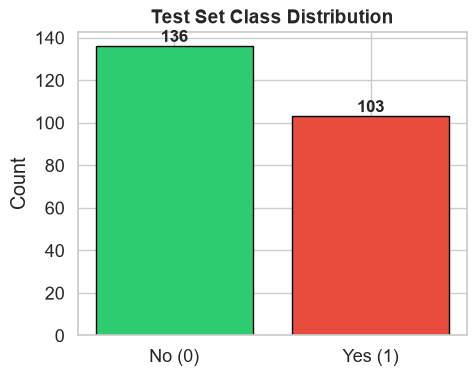

In [12]:
# Display class distribution for the test set
test_counts = y_test.value_counts()
print("Test Set Class Distribution:")
for label, count in test_counts.items():
    print(f"Class {label}: {count} ({count/len(y_test)*100:.2f}%)")

import matplotlib.pyplot as plt
plt.figure(figsize=(5,4))
colors = ['#2ecc71', '#e74c3c']
plt.bar(['No (0)', 'Yes (1)'], [test_counts.get(0,0), test_counts.get(1,0)], color=colors, edgecolor='black')
plt.title('Test Set Class Distribution', fontsize=14, fontweight='bold')
plt.ylabel('Count')
for i, count in enumerate([test_counts.get(0,0), test_counts.get(1,0)]):
    plt.text(i, count + 2, f'{count}', ha='center', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

## Summary & Final Output


In [13]:
# Improved Preprocessing Summary
print("="*80)
print("PREPROCESSING SUMMARY")
print("="*80)
print(f"""
1. IRRELEVANT FEATURE REMOVAL
   - Removed: {len(features_to_remove) if 'features_to_remove' in globals() and features_to_remove is not None else 0} constant/admin features
   - Reason: Features with uniform values don't contribute to prediction

2. CATEGORICAL STANDARDISATION
   - Cleaned irregular spacing and capitalization
   - Ensures consistent category recognition

3. RARE CATEGORY GROUPING
   - Threshold: <{rare_threshold*100:.0f}% of records
   - Categories below threshold grouped as 'Other'

4. OUTLIER DETECTION (NO ROWS REMOVED) (Z-SCORE)
   - Method: Removed records with |Z| > 3
   - Rows removed: {total_outlier_rows if 'total_outlier_rows' in globals() else 'N/A'}

5. TARGET ENCODING
   - Attrition: Yes/No → 1/0 (binary)

6. CATEGORICAL ENCODING
   - Binary columns: {len(binary_cols) if 'binary_cols' in globals() else 'N/A'} (Label Encoding)
   - Ordinal columns: {len(ordinal_cols_present) if 'ordinal_cols_present' in globals() else 'N/A'} (OrdinalEncoder)
   - Nominal columns: {len(nominal_cols) if 'nominal_cols' in globals() else 'N/A'} (M-Estimator Target Encoding)

FINAL DATASET:
   - Rows: {len(df_encoded) if 'df_encoded' in globals() else len(df)}
   - Columns: {(df_encoded.shape[1] if 'df_encoded' in globals() else df.shape[1])}
   - Ready for machine learning modeling.
""")
print("="*80)


PREPROCESSING SUMMARY

1. IRRELEVANT FEATURE REMOVAL
   - Removed: 1 constant/admin features
   - Reason: Features with uniform values don't contribute to prediction

2. CATEGORICAL STANDARDISATION
   - Cleaned irregular spacing and capitalization
   - Ensures consistent category recognition

3. RARE CATEGORY GROUPING
   - Threshold: <1% of records
   - Categories below threshold grouped as 'Other'

4. OUTLIER DETECTION (NO ROWS REMOVED) (Z-SCORE)
   - Method: Removed records with |Z| > 3
   - Rows removed: 0

5. TARGET ENCODING
   - Attrition: Yes/No → 1/0 (binary)

6. CATEGORICAL ENCODING
   - Binary columns: 11 (Label Encoding)
   - Ordinal columns: 17 (OrdinalEncoder)
   - Nominal columns: 4 (M-Estimator Target Encoding)

FINAL DATASET:
   - Rows: 1191
   - Columns: 34
   - Ready for machine learning modeling.



In [14]:
# Display first few rows of the encoded data (ready for ML)
print("Preprocessed DataFrame (Encoded - Ready for ML):")
print(f"Shape: {df.shape}")
pd.set_option('display.max_columns', None)
df.head()

Preprocessed DataFrame (Encoded - Ready for ML):
Shape: (1191, 34)


,Attrition,Gender,Age,Maritalstatus,Academic_degree,Years_Experience,Years_experience_lastorganization,Sector,Department,JobTitle,MonthlySalary,Allowances,MedicalInsurance,Bonus,OverTime,Payment_Overtime,Rewards_Wages_Satisfaction,Get_Deserved_Promotion,Training_programs_During_last_three_years,Useful_Training_Programs,Business_Travel,Job_Support,Recognition,Emotional_Commitment,Job_Engagement,Distance_to_work,Work_Live_Balance,Physical_Stress,Psychological_Exhaustion,Job_Stability,Health_Issues,Environment_Satisfaction,Job_Satisfaction,Job_Opportunities
0,1,Female,31 to 40,Married,Master's,Less than 5 years,Less than 5 years,Medical sector,Accounting,Accountant,From 5000 to 10000 S.R,2,No,No,No,I don't have overtime,Yes,Yes,From 1 to 3 training programs,Yes,I do not travel for work,Medium,No,Medium,Medium,Medium,Medium,Yes,No,No,Yes,Medium,Not satisfied,Yes
1,0,Female,21 to 30,Single,Master's,Less than 5 years,Less than 5 years,Medical sector,Accounting,Accountant,From 11000 to 15000 S.R,2,Yes,Yes,No,I don't have overtime,Yes,Yes,From 1 to 3 training programs,Yes,Travel rarely,Medium,Yes,Medium,Medium,Medium,Medium,No,No,Yes,No,Medium,Satisfied,No
2,0,Female,21 to 30,Single,Bachelor's,Less than 5 years,Less than 5 years,Education sector,Teaching,Teacher,Less than 5000 SAR,0,No,No,No,I don't have overtime,No,No,From 1 to 3 training programs,Yes,I do not travel for work,Medium,Yes,Low,Medium,Close,Medium,Yes,Sometimes,No,No,Medium,Satisfied,Yes
3,0,Female,21 to 30,Single,Bachelor's,Less than 5 years,Less than 5 years,Education sector,Teaching,Teacher,Less than 5000 SAR,0,No,No,No,I don't have overtime,No,No,I did not receive any training,No,I do not travel for work,Low,No,Low,Medium,Medium,Medium,Yes,Yes,No,No,Low,Not satisfied,No
4,0,Female,21 to 30,Single,Bachelor's,Less than 5 years,Less than 5 years,Education sector,Teaching,Teacher,Less than 5000 SAR,0,No,No,Yes,No,No,No,I did not receive any training,No,I do not travel for work,Low,Yes,Medium,Medium,Medium,Medium,Sometimes,Sometimes,No,No,Medium,Not satisfied,No


In [15]:
from pathlib import Path
from datetime import datetime

export_path = Path("saudi_preprocessed.csv")

# try:
df.to_csv(export_path, index=False)
saved_path = export_path

print(f"Preprocessed dataset saved to {saved_path.resolve()}")
print(f"Shape: {df.shape}")
df.head()

Preprocessed dataset saved to D:\MMU\Albertus-fyp\fyp\saudi\saudi_preprocessed.csv
Shape: (1191, 34)


,Attrition,Gender,Age,Maritalstatus,Academic_degree,Years_Experience,Years_experience_lastorganization,Sector,Department,JobTitle,MonthlySalary,Allowances,MedicalInsurance,Bonus,OverTime,Payment_Overtime,Rewards_Wages_Satisfaction,Get_Deserved_Promotion,Training_programs_During_last_three_years,Useful_Training_Programs,Business_Travel,Job_Support,Recognition,Emotional_Commitment,Job_Engagement,Distance_to_work,Work_Live_Balance,Physical_Stress,Psychological_Exhaustion,Job_Stability,Health_Issues,Environment_Satisfaction,Job_Satisfaction,Job_Opportunities
0,1,Female,31 to 40,Married,Master's,Less than 5 years,Less than 5 years,Medical sector,Accounting,Accountant,From 5000 to 10000 S.R,2,No,No,No,I don't have overtime,Yes,Yes,From 1 to 3 training programs,Yes,I do not travel for work,Medium,No,Medium,Medium,Medium,Medium,Yes,No,No,Yes,Medium,Not satisfied,Yes
1,0,Female,21 to 30,Single,Master's,Less than 5 years,Less than 5 years,Medical sector,Accounting,Accountant,From 11000 to 15000 S.R,2,Yes,Yes,No,I don't have overtime,Yes,Yes,From 1 to 3 training programs,Yes,Travel rarely,Medium,Yes,Medium,Medium,Medium,Medium,No,No,Yes,No,Medium,Satisfied,No
2,0,Female,21 to 30,Single,Bachelor's,Less than 5 years,Less than 5 years,Education sector,Teaching,Teacher,Less than 5000 SAR,0,No,No,No,I don't have overtime,No,No,From 1 to 3 training programs,Yes,I do not travel for work,Medium,Yes,Low,Medium,Close,Medium,Yes,Sometimes,No,No,Medium,Satisfied,Yes
3,0,Female,21 to 30,Single,Bachelor's,Less than 5 years,Less than 5 years,Education sector,Teaching,Teacher,Less than 5000 SAR,0,No,No,No,I don't have overtime,No,No,I did not receive any training,No,I do not travel for work,Low,No,Low,Medium,Medium,Medium,Yes,Yes,No,No,Low,Not satisfied,No
4,0,Female,21 to 30,Single,Bachelor's,Less than 5 years,Less than 5 years,Education sector,Teaching,Teacher,Less than 5000 SAR,0,No,No,Yes,No,No,No,I did not receive any training,No,I do not travel for work,Low,Yes,Medium,Medium,Medium,Medium,Sometimes,Sometimes,No,No,Medium,Not satisfied,No


In [16]:
import numpy as np
from skrebate import ReliefF, MultiSURF

print("="*60)
print("FEATURE SELECTION - ReliefF AND MultiSURF")
print("="*60)

# Ranking is fitted once on the training partition only. The held-out test set is
# never used for ranking. CV below is used to select the smallest useful top-N subset.
feature_names = X_train.columns.tolist()
X_train_np = np.asarray(X_train, dtype=float)
y_train_np = np.asarray(y_train)

print(f"\nFeature matrix for ranking: {X_train.shape}")
print(f"Target distribution used for ranking: No={sum(y_train==0)}, Yes={sum(y_train==1)}")

print("ReliefF Feature Ranking")
print("-"*60)

relieff = ReliefF(n_features_to_select=X_train_np.shape[1], n_neighbors=100)
relieff.fit(X_train_np, y_train_np)
relieff_scores_dict = dict(zip(feature_names, relieff.feature_importances_))
relieff_sorted = sorted(relieff_scores_dict.items(), key=lambda x: x[1], reverse=True)

print("\nAll Features Ranked by ReliefF Score:")
for i, (feat, score) in enumerate(relieff_sorted, 1):
    print(f"  {i:2d}. {feat}: {score:.4f}")


FEATURE SELECTION - ReliefF AND MultiSURF

Feature matrix for ranking: (952, 33)
Target distribution used for ranking: No=540, Yes=412
ReliefF Feature Ranking
------------------------------------------------------------

All Features Ranked by ReliefF Score:
   1. Job_Opportunities: 0.1530
   2. JobTitle: 0.0845
   3. Years_Experience: 0.0776
   4. Sector: 0.0673
   5. Emotional_Commitment: 0.0640
   6. Job_Stability: 0.0628
   7. Get_Deserved_Promotion: 0.0558
   8. Rewards_Wages_Satisfaction: 0.0535
   9. Job_Support: 0.0500
  10. Years_experience_lastorganization: 0.0444
  11. Department: 0.0429
  12. Allowances: 0.0348
  13. Training_programs_During_last_three_years: 0.0319
  14. Job_Satisfaction: 0.0310
  15. Psychological_Exhaustion: 0.0306
  16. Distance_to_work: 0.0236
  17. Work_Live_Balance: 0.0221
  18. Job_Engagement: 0.0218
  19. Useful_Training_Programs: 0.0216
  20. MedicalInsurance: 0.0205
  21. Recognition: 0.0202
  22. Payment_Overtime: 0.0200
  23. Physical_Stress: 0

In [17]:
print("MultiSURF Feature Ranking")
print("-"*60)

multisurf = MultiSURF(n_features_to_select=X_train_np.shape[1])
multisurf.fit(X_train_np, y_train_np)
multisurf_scores_dict = dict(zip(feature_names, multisurf.feature_importances_))
multisurf_sorted = sorted(multisurf_scores_dict.items(), key=lambda x: x[1], reverse=True)

print("\nAll Features Ranked by MultiSURF Score:")
for i, (feat, score) in enumerate(multisurf_sorted, 1):
    print(f"  {i:2d}. {feat}: {score:.4f}")


MultiSURF Feature Ranking
------------------------------------------------------------

All Features Ranked by MultiSURF Score:
   1. Job_Opportunities: 0.1396
   2. JobTitle: 0.0757
   3. Sector: 0.0540
   4. Years_Experience: 0.0451
   5. Job_Stability: 0.0394
   6. Emotional_Commitment: 0.0377
   7. Get_Deserved_Promotion: 0.0306
   8. Department: 0.0297
   9. Rewards_Wages_Satisfaction: 0.0271
  10. Job_Support: 0.0183
  11. Years_experience_lastorganization: 0.0138
  12. Allowances: 0.0127
  13. Training_programs_During_last_three_years: 0.0084
  14. Health_Issues: 0.0054
  15. Recognition: 0.0051
  16. Job_Engagement: 0.0044
  17. Psychological_Exhaustion: 0.0035
  18. Job_Satisfaction: 0.0031
  19. MedicalInsurance: 0.0020
  20. Distance_to_work: 0.0020
  21. Work_Live_Balance: 0.0006
  22. Useful_Training_Programs: 0.0005
  23. Physical_Stress: -0.0055
  24. Gender: -0.0088
  25. Business_Travel: -0.0099
  26. MonthlySalary: -0.0105
  27. Academic_degree: -0.0117
  28. Payment_

In [18]:
# Export Feature Rankings to Excel (Original Feature Order)
import pandas as pd

# Create DataFrame with original feature order
feature_ranking_df = pd.DataFrame({
    'Feature': feature_names,
    'ReliefF_Score': [relieff_scores_dict[f] for f in feature_names],
    'MultiSURF_Score': [multisurf_scores_dict[f] for f in feature_names]
})

# Add ranking columns (1=best, higher numbers=lower rank)
feature_ranking_df['ReliefF_Rank'] = feature_ranking_df['ReliefF_Score'].rank(ascending=False, method='min').astype(int)
feature_ranking_df['MultiSURF_Rank'] = feature_ranking_df['MultiSURF_Score'].rank(ascending=False, method='min').astype(int)

# Export to Excel
export_filename = 'saudi_feature_rankings.xlsx'
feature_ranking_df.to_excel(export_filename, index=False, sheet_name='Feature Rankings')

print(f"✓ Feature rankings exported to: {export_filename}")
print(f"✓ Total features: {len(feature_ranking_df)}")
print(f"\nPreview (first 5 features in original order):")
print(feature_ranking_df.head())


✓ Feature rankings exported to: saudi_feature_rankings.xlsx
✓ Total features: 33

Preview (first 5 features in original order):
            Feature  ReliefF_Score  MultiSURF_Score  ReliefF_Rank  \
0            Gender       0.010368        -0.008754            25   
1               Age       0.009307        -0.015153            28   
2     Maritalstatus       0.008739        -0.015651            29   
3   Academic_degree       0.003162        -0.011707            32   
4  Years_Experience       0.077584         0.045121             3   

   MultiSURF_Rank  
0              24  
1              29  
2              30  
3              27  
4               4  


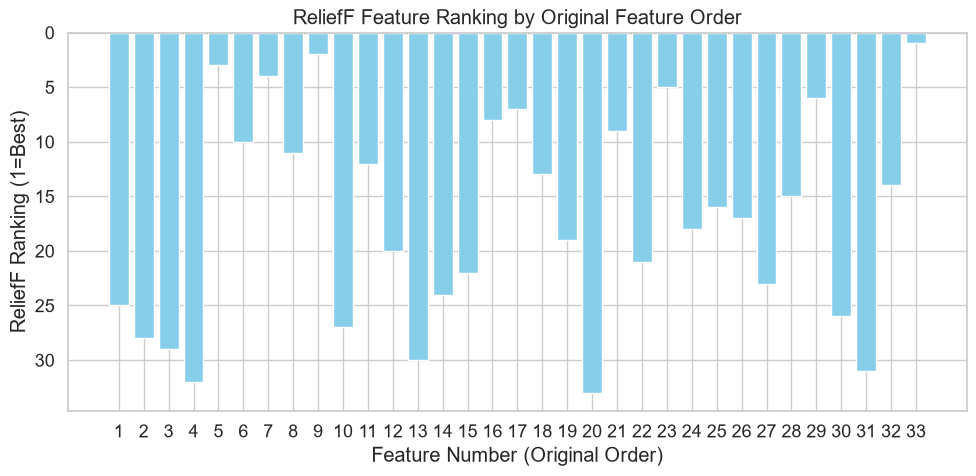

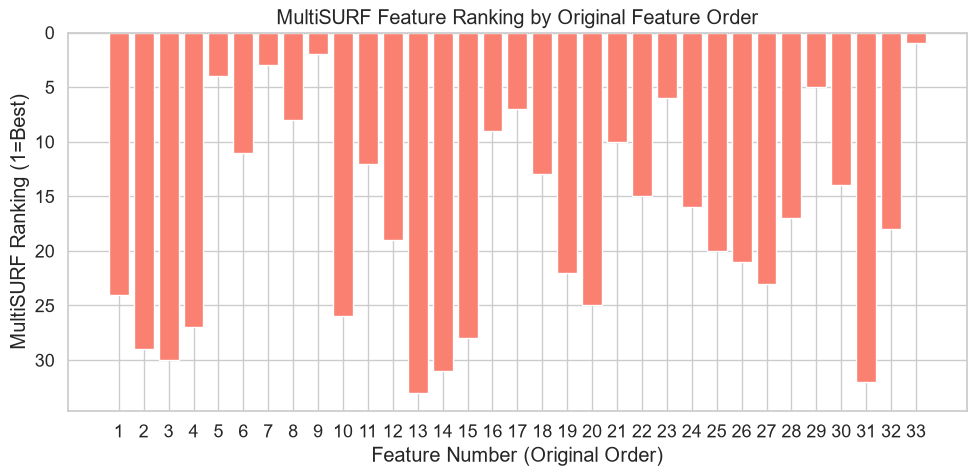

In [19]:
# Visualization: Feature Ranking (Y=Ranking, X=Feature Number, Original Order)
import matplotlib.pyplot as plt
import numpy as np

# Get feature names in original order
feature_numbers = np.arange(1, len(feature_names)+1)

# ReliefF: get ranking for each feature in original order
relieff_ranking = [
    [feat for feat, _ in relieff_sorted].index(f) + 1 for f in feature_names
]
plt.figure(figsize=(10, 5))
plt.bar(feature_numbers, relieff_ranking, color='skyblue')
plt.ylabel('ReliefF Ranking (1=Best)')
plt.xlabel('Feature Number (Original Order)')
plt.title('ReliefF Feature Ranking by Original Feature Order')
plt.xticks(feature_numbers)
plt.gca().invert_yaxis()  # 1 is best, so invert
plt.tight_layout()
plt.show()

# MultiSURF: get ranking for each feature in original order
multisurf_ranking = [
    [feat for feat, _ in multisurf_sorted].index(f) + 1 for f in feature_names
]
plt.figure(figsize=(10, 5))
plt.bar(feature_numbers, multisurf_ranking, color='salmon')
plt.ylabel('MultiSURF Ranking (1=Best)')
plt.xlabel('Feature Number (Original Order)')
plt.title('MultiSURF Feature Ranking by Original Feature Order')
plt.xticks(feature_numbers)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [20]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier, VotingClassifier, GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

print("="*60)
print("F1-OPTIMISED MODEL TUNING AND VOTING EVALUATION - IBM")
print("="*60)

scoring_metric = "f1"
cv_splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

rf_param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 5, 10],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
}
xgb_param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.1, 0.3],
    "subsample": [0.8, 1.0],
}
svm_param_grid = {
    "C": [0.1, 1, 10],
    "kernel": ["rbf"],
    "gamma": ["scale", "auto"],
}
dt_param_grid = {
    "max_depth": [None, 5, 10],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
}
gb_param_grid = {
    "n_estimators": [100, 200],
    "learning_rate": [0.05, 0.1],
    "max_depth": [3, 5],
    "subsample": [0.8, 1.0],
}

def prefix_grid(grid, prefix="clf"):
    return {f"{prefix}__{k}": v for k, v in grid.items()}

def build_model_pipeline(estimator, use_smote=True, smote_seed=None):
    steps = [
        ("target_encode", MEstimateTargetEncoder(columns=nominal_cols, m=m_value)),
        ("scale", StandardScaler()),
    ]
    if use_smote:
        steps.append(("smote", SMOTE(random_state=SEED if smote_seed is None else smote_seed)))
    steps.append(("clf", estimator))
    return ImbPipeline(steps)

def tune_model(estimator, grid):
    pipeline = build_model_pipeline(estimator)
    search = GridSearchCV(
        pipeline,
        prefix_grid(grid),
        cv=cv_splitter,
        scoring=scoring_metric,
        n_jobs=-1,
        refit=True,
    )
    search.fit(X_train_raw_model, y_train)
    print(f"{estimator.__class__.__name__} best CV F1: {search.best_score_:.4f}")
    print(f"  best parameters: {search.best_params_}")
    return search

gs_rf = tune_model(RandomForestClassifier(random_state=SEED), rf_param_grid)
gs_xgb = tune_model(XGBClassifier(random_state=SEED, eval_metric="logloss"), xgb_param_grid)
gs_svm = tune_model(SVC(probability=True, random_state=SEED), svm_param_grid)
gs_dt = tune_model(DecisionTreeClassifier(random_state=SEED), dt_param_grid)
gs_gb = tune_model(GradientBoostingClassifier(random_state=SEED), gb_param_grid)

# Use the tuned classifier settings as the voting components. Preprocessing and
# SMOTE are applied by build_model_pipeline inside each CV fold.
rf = clone(gs_rf.best_estimator_.named_steps["clf"])
xgb = clone(gs_xgb.best_estimator_.named_steps["clf"])
svm = clone(gs_svm.best_estimator_.named_steps["clf"])
dt = clone(gs_dt.best_estimator_.named_steps["clf"])
gb = clone(gs_gb.best_estimator_.named_steps["clf"])

voting_clf = VotingClassifier(
    estimators=[("rf", clone(rf)), ("gb", clone(gb)), ("svm", clone(svm)), ("dt", clone(dt))],
    voting="soft",
)
voting_clf_hard = VotingClassifier(
    estimators=[("rf", clone(rf)), ("gb", clone(gb)), ("svm", clone(svm)), ("dt", clone(dt))],
    voting="hard",
)

# Every voting combination is evaluated and optimized independently. The
# additional combinations are shown in tables but are not added to the main
# top-N figure.
voting_models = {
    "General Voting": voting_clf,
    "Hard Voting": voting_clf_hard,
    "Voting GB + XGBoost (equal weights)": VotingClassifier(
        estimators=[("gb", clone(gb)), ("xgb", clone(xgb))],
        voting="soft",
    ),
    "Voting RF + XGBoost": VotingClassifier(
        estimators=[("rf", clone(rf)), ("xgb", clone(xgb))],
        voting="soft",
    ),
    "Voting GB + SVM": VotingClassifier(
        estimators=[("gb", clone(gb)), ("svm", clone(svm))],
        voting="soft",
    ),
    "Voting GB + XGBoost + SVM": VotingClassifier(
        estimators=[("gb", clone(gb)), ("xgb", clone(xgb)), ("svm", clone(svm))],
        voting="soft",
    ),
    "Voting RF + GB + XGBoost": VotingClassifier(
        estimators=[("rf", clone(rf)), ("gb", clone(gb)), ("xgb", clone(xgb))],
        voting="soft",
    ),
    "Voting All Five": VotingClassifier(
        estimators=[("rf", clone(rf)), ("gb", clone(gb)), ("xgb", clone(xgb)), ("svm", clone(svm)), ("dt", clone(dt))],
        voting="soft",
    ),
}

cv_models = {
    "Random Forest": rf,
    "XGBoost": xgb,
    "SVM": svm,
    "Decision Tree": dt,
    "Gradient Boosting": gb,
}
cv_models.update(voting_models)

cv_results = []
for name, estimator in cv_models.items():
    scores = cross_val_score(
        build_model_pipeline(clone(estimator)),
        X_train_raw_model,
        y_train,
        cv=cv_splitter,
        scoring="f1",
        n_jobs=-1,
    )
    cv_results.append({"Model": name, "Mean CV F1": scores.mean(), "Std CV F1": scores.std()})
    print(f"{name}: mean CV F1={scores.mean():.4f}, std={scores.std():.4f}")

cv_results = pd.DataFrame(cv_results)
display(cv_results.sort_values("Mean CV F1", ascending=False).round(4))

def positive_scores(fitted_model, X):
    """Return a continuous positive-class score for ROC/PR metrics."""
    try:
        return fitted_model.predict_proba(X)[:, 1]
    except (AttributeError, NotImplementedError):
        if hasattr(fitted_model, "decision_function"):
            return fitted_model.decision_function(X)
        return fitted_model.predict(X)

def run_to_run_variance(estimator, X_features, y_target, model_name, seeds=(SEED, SEED + 1, SEED + 2)):
    """Evaluate CV-F1 stability across seeds for a fixed feature subset."""
    rows = []
    for run_seed in seeds:
        run_estimator = clone(estimator)
        seed_params = {
            name: run_seed
            for name in run_estimator.get_params(deep=True)
            if name.endswith("random_state")
        }
        if seed_params:
            run_estimator.set_params(**seed_params)
        run_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=run_seed)
        run_scores = cross_val_score(
            build_model_pipeline(run_estimator, smote_seed=run_seed),
            X_features,
            y_target,
            cv=run_cv,
            scoring="f1",
            n_jobs=-1,
        )
        rows.append({"Model": model_name, "Seed": run_seed, "Mean CV F1": run_scores.mean(), "Fold SD": run_scores.std()})
    return pd.DataFrame(rows)


F1-OPTIMISED MODEL TUNING AND VOTING EVALUATION - IBM
RandomForestClassifier best CV F1: 0.7689
  best parameters: {'clf__max_depth': 10, 'clf__min_samples_leaf': 1, 'clf__min_samples_split': 5, 'clf__n_estimators': 200}
XGBClassifier best CV F1: 0.7872
  best parameters: {'clf__learning_rate': 0.1, 'clf__max_depth': 3, 'clf__n_estimators': 200, 'clf__subsample': 1.0}
SVC best CV F1: 0.7686
  best parameters: {'clf__C': 1, 'clf__gamma': 'scale', 'clf__kernel': 'rbf'}
DecisionTreeClassifier best CV F1: 0.7128
  best parameters: {'clf__max_depth': 5, 'clf__min_samples_leaf': 2, 'clf__min_samples_split': 2}
GradientBoostingClassifier best CV F1: 0.7893
  best parameters: {'clf__learning_rate': 0.05, 'clf__max_depth': 3, 'clf__n_estimators': 200, 'clf__subsample': 1.0}
Random Forest: mean CV F1=0.7689, std=0.0418
XGBoost: mean CV F1=0.7872, std=0.0165
SVM: mean CV F1=0.7686, std=0.0287
Decision Tree: mean CV F1=0.7128, std=0.0200
Gradient Boosting: mean CV F1=0.7893, std=0.0140
General Vot

,Model,Mean CV F1,Std CV F1
9,Voting GB + SVM,0.7955,0.0265
10,Voting GB + XGBoost + SVM,0.7918,0.0244
4,Gradient Boosting,0.7893,0.0140
7,Voting GB + XGBoost (equal weights),0.7893,0.0124
11,Voting RF + GB + XGBoost,0.7883,0.0105
1,XGBoost,0.7872,0.0165
8,Voting RF + XGBoost,0.7869,0.0198
12,Voting All Five,0.7796,0.0251
5,General Voting,0.7697,0.0262
0,Random Forest,0.7689,0.0418


In [21]:
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.model_selection import cross_val_score

print("="*60)
print("TOP-N FEATURE CURVES USING F1 - IBM")
print("="*60)

max_n = len(feature_names)
cv_folds = cv_splitter
scoring = "f1"

base_model_templates = {
    "Random Forest": rf,
    "XGBoost": xgb,
    "SVM": svm,
    "Decision Tree": dt,
    "Gradient Boosting": gb,
}
model_templates = {**base_model_templates, **voting_models}

def evaluate_top_n(selected_features, estimator):
    X_subset = X_train_raw_model.loc[:, selected_features]
    return cross_val_score(
        build_model_pipeline(clone(estimator)),
        X_subset,
        y_train,
        cv=cv_folds,
        scoring=scoring,
        n_jobs=-1,
    ).mean()

scores = {
    "relief": {name: [] for name in model_templates},
    "multi": {name: [] for name in model_templates},
}

for n in range(1, max_n + 1):
    relief_features = [feature for feature, _ in relieff_sorted[:n]]
    multi_features = [feature for feature, _ in multisurf_sorted[:n]]
    for name, estimator in model_templates.items():
        scores["relief"][name].append(evaluate_top_n(relief_features, estimator))
        scores["multi"][name].append(evaluate_top_n(multi_features, estimator))

# Preserve the existing variables used by the base-model plot. All remaining
# voting models are optimized above and reported in a separate table.
rf_acc_relief = scores["relief"]["Random Forest"]
xgb_acc_relief = scores["relief"]["XGBoost"]
svm_acc_relief = scores["relief"]["SVM"]
dt_acc_relief = scores["relief"]["Decision Tree"]
gb_acc_relief = scores["relief"]["Gradient Boosting"]
voting_clf_acc_relief = scores["relief"]["General Voting"]
voting_clf_hard_acc_relief = scores["relief"]["Hard Voting"]
rf_acc_multi = scores["multi"]["Random Forest"]
xgb_acc_multi = scores["multi"]["XGBoost"]
svm_acc_multi = scores["multi"]["SVM"]
dt_acc_multi = scores["multi"]["Decision Tree"]
gb_acc_multi = scores["multi"]["Gradient Boosting"]
voting_clf_acc_multi = scores["multi"]["General Voting"]
voting_clf_hard_acc_multi = scores["multi"]["Hard Voting"]

def first_argmax(values):
    maximum = max(values)
    return next(i + 1 for i, value in enumerate(values) if value >= maximum)

best_feature_counts = {
    selector_name: {
        model_name: first_argmax(model_scores)
        for model_name, model_scores in selector_scores.items()
    }
    for selector_name, selector_scores in [
        ("ReliefF", scores["relief"]),
        ("MultiSURF", scores["multi"]),
    ]
}

best_cv_f1 = {
    selector_name: {
        model_name: max(model_scores)
        for model_name, model_scores in selector_scores.items()
    }
    for selector_name, selector_scores in [
        ("ReliefF", scores["relief"]),
        ("MultiSURF", scores["multi"]),
    ]
}

# Compatibility aliases for the base-model reporting cells.
best_rf_relief = best_feature_counts["ReliefF"]["Random Forest"]
best_xgb_relief = best_feature_counts["ReliefF"]["XGBoost"]
best_svm_relief = best_feature_counts["ReliefF"]["SVM"]
best_dt_relief = best_feature_counts["ReliefF"]["Decision Tree"]
best_gb_relief = best_feature_counts["ReliefF"]["Gradient Boosting"]
best_voting_relief = best_feature_counts["ReliefF"]["General Voting"]
best_voting_hard_relief = best_feature_counts["ReliefF"]["Hard Voting"]
best_rf_multi = best_feature_counts["MultiSURF"]["Random Forest"]
best_xgb_multi = best_feature_counts["MultiSURF"]["XGBoost"]
best_svm_multi = best_feature_counts["MultiSURF"]["SVM"]
best_dt_multi = best_feature_counts["MultiSURF"]["Decision Tree"]
best_gb_multi = best_feature_counts["MultiSURF"]["Gradient Boosting"]
best_voting_multi = best_feature_counts["MultiSURF"]["General Voting"]
best_voting_hard_multi = best_feature_counts["MultiSURF"]["Hard Voting"]

voting_feature_rows = []
for selector_name in ("ReliefF", "MultiSURF"):
    selector_key = selector_name.lower().replace("f", "")
    # MultiSURF is stored under "multi"; ReliefF under "relief".
    selector_key = "relief" if selector_name == "ReliefF" else "multi"
    for model_name in voting_models:
        n = best_feature_counts[selector_name][model_name]
        voting_feature_rows.append({
            "Feature Selection": selector_name,
            "Model": model_name,
            "Optimal Features": n,
            "Best CV F1": best_cv_f1[selector_name][model_name],
        })
voting_feature_summary = pd.DataFrame(voting_feature_rows)
print("Each voting classifier uses its own top-N CV-F1 optimum:")
display(voting_feature_summary.sort_values(["Feature Selection", "Best CV F1"], ascending=[True, False]).round(4))
print("Feature-count rule: choose the smallest N attaining the maximum mean CV F1 for that model and selector.")


TOP-N FEATURE CURVES USING F1 - IBM
Each voting classifier uses its own top-N CV-F1 optimum:


,Feature Selection,Model,Optimal Features,Best CV F1
12,MultiSURF,Voting GB + SVM,20,0.8022
13,MultiSURF,Voting GB + XGBoost + SVM,32,0.7957
15,MultiSURF,Voting All Five,22,0.7899
10,MultiSURF,Voting GB + XGBoost (equal weights),33,0.7893
14,MultiSURF,Voting RF + GB + XGBoost,32,0.7889
11,MultiSURF,Voting RF + XGBoost,31,0.7885
8,MultiSURF,General Voting,18,0.7806
9,MultiSURF,Hard Voting,14,0.7741
4,ReliefF,Voting GB + SVM,24,0.8067
5,ReliefF,Voting GB + XGBoost + SVM,25,0.8020


Feature-count rule: choose the smallest N attaining the maximum mean CV F1 for that model and selector.


Focused feature-selection comparison - XGBoost - Saudi


,Feature Selection,Model,Optimal Features,Best Mean CV F1
0,ReliefF,XGBoost,22,0.7906
1,MultiSURF,XGBoost,33,0.7872


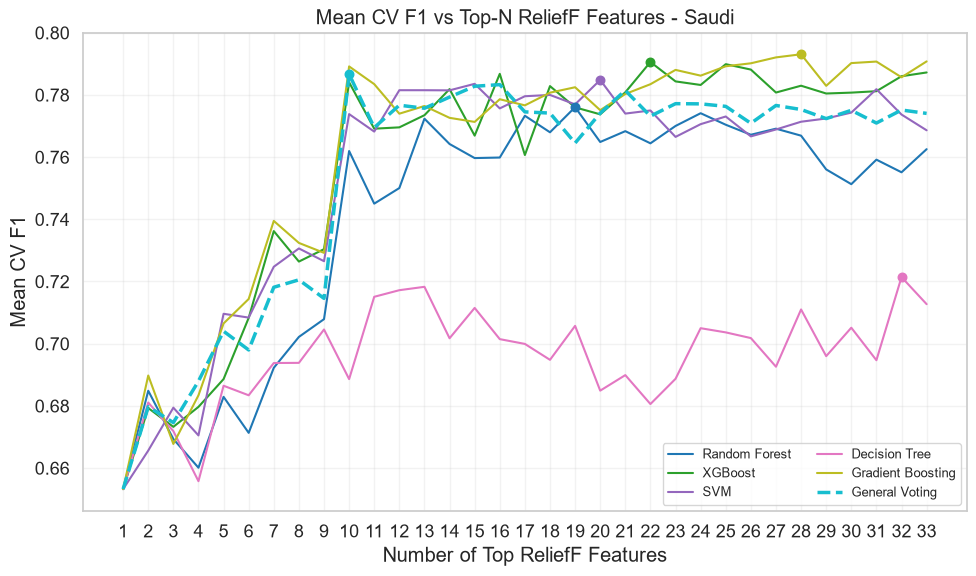

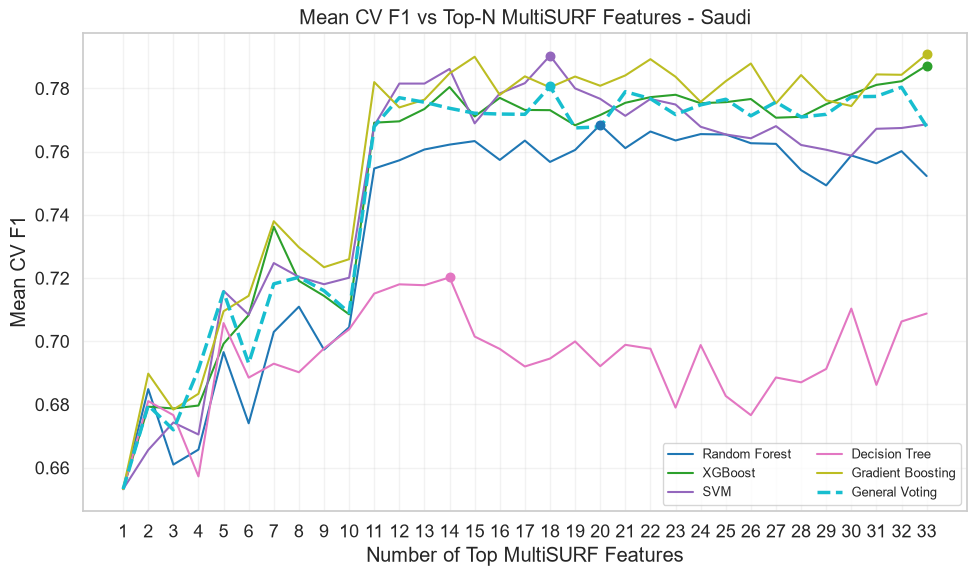

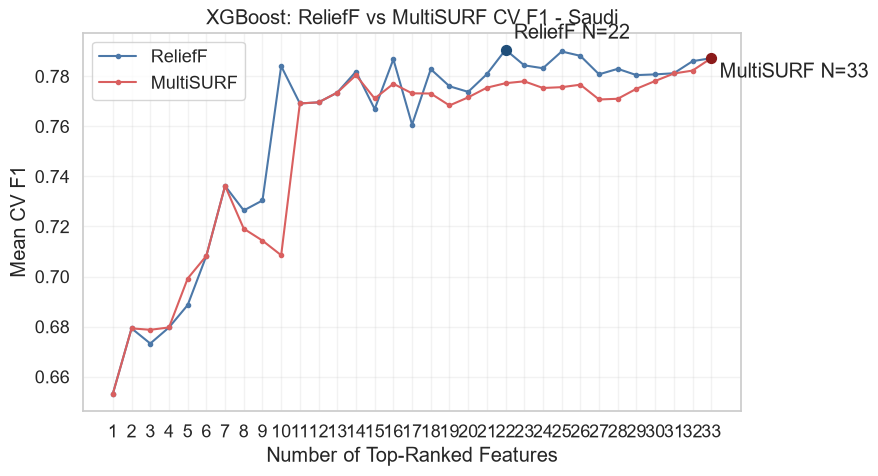

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Compare feature-count curves for the five individual classifiers and the
# paper's general soft-voting classifier. Other voting ablations remain in tables.
focus_model_name = "XGBoost"
n_values = np.arange(1, max_n + 1)
comparison_model_names = list(base_model_templates.keys()) + ["General Voting"]
missing_curve_models = [
    name for name in comparison_model_names
    if name not in scores["relief"] or name not in scores["multi"]
]
if missing_curve_models:
    raise KeyError(f"Missing Top-N CV curves for: {missing_curve_models}")

focus_relief_cv = np.asarray(scores["relief"][focus_model_name], dtype=float)
focus_multi_cv = np.asarray(scores["multi"][focus_model_name], dtype=float)
focus_relief_n = best_feature_counts["ReliefF"][focus_model_name]
focus_multi_n = best_feature_counts["MultiSURF"][focus_model_name]

fs_cv_comparison = pd.DataFrame({
    "Feature Selection": ["ReliefF", "MultiSURF"],
    "Model": [focus_model_name, focus_model_name],
    "Optimal Features": [focus_relief_n, focus_multi_n],
    "Best Mean CV F1": [focus_relief_cv[focus_relief_n - 1], focus_multi_cv[focus_multi_n - 1]],
})
print(f"Focused feature-selection comparison - {focus_model_name} - Saudi")
display(fs_cv_comparison.round(4))

def plot_top_n_curves(score_key, selector_name):
    plt.figure(figsize=(10, 6))
    colours = plt.cm.tab10(np.linspace(0, 1, len(comparison_model_names)))
    for colour, model_name in zip(colours, comparison_model_names):
        curve = np.asarray(scores[score_key][model_name], dtype=float)
        optimal_n = best_feature_counts[selector_name][model_name]
        is_voting = model_name == "General Voting"
        plt.plot(
            n_values, curve,
            label=model_name,
            color=colour,
            linewidth=2.5 if is_voting else 1.5,
            linestyle="--" if is_voting else "-",
        )
        plt.scatter(optimal_n, curve[optimal_n - 1], color=colour, s=38, zorder=3)
    plt.xlabel(f"Number of Top {selector_name} Features")
    plt.ylabel("Mean CV F1")
    plt.title(f"Mean CV F1 vs Top-N {selector_name} Features - Saudi")
    plt.xticks(n_values)
    plt.legend(ncol=2, fontsize=9)
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

# Figure 1: all individual models and General Voting using ReliefF rankings.
plot_top_n_curves("relief", "ReliefF")

# Figure 2: all individual models and General Voting using MultiSURF rankings.
plot_top_n_curves("multi", "MultiSURF")

# Figure 3: matched selector comparison for the dataset's selected best model.
plt.figure(figsize=(9, 5))
plt.plot(n_values, focus_relief_cv, marker="o", markersize=3, label="ReliefF", color="#4C78A8")
plt.plot(n_values, focus_multi_cv, marker="o", markersize=3, label="MultiSURF", color="#D95F5F")
plt.scatter(focus_relief_n, focus_relief_cv[focus_relief_n - 1], color="#1F4E79", s=50, zorder=3)
plt.scatter(focus_multi_n, focus_multi_cv[focus_multi_n - 1], color="#8B1A1A", s=50, zorder=3)
plt.annotate(f"ReliefF N={focus_relief_n}", (focus_relief_n, focus_relief_cv[focus_relief_n - 1]),
             xytext=(6, 8), textcoords="offset points")
plt.annotate(f"MultiSURF N={focus_multi_n}", (focus_multi_n, focus_multi_cv[focus_multi_n - 1]),
             xytext=(6, -14), textcoords="offset points")
plt.xlabel("Number of Top-Ranked Features")
plt.ylabel("Mean CV F1")
plt.title(f"{focus_model_name}: ReliefF vs MultiSURF CV F1 - Saudi")
plt.xticks(n_values)
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


In [23]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score

print("="*60)
print("FINAL HOLDOUT TEST EVALUATION - Saudi")
print("="*60)

rankings = {"ReliefF": relieff_sorted, "MultiSURF": multisurf_sorted}
model_templates = {**base_model_templates, **voting_models}
model_sizes = {
    selector_name: {
        model_name: best_feature_counts[selector_name][model_name]
        for model_name in model_templates
    }
    for selector_name in rankings
}
cv_arrays = {
    "ReliefF": scores["relief"],
    "MultiSURF": scores["multi"],
}

test_results = []
final_models = {}
for selector_name, ranking in rankings.items():
    for model_name, estimator in model_templates.items():
        n = model_sizes[selector_name][model_name]
        selected_features = [feature for feature, _ in ranking[:n]]
        model_pipeline = build_model_pipeline(clone(estimator))
        model_pipeline.fit(X_train_raw_model.loc[:, selected_features], y_train)
        X_eval = X_test_raw_model.loc[:, selected_features]
        y_pred = model_pipeline.predict(X_eval)
        y_score = positive_scores(model_pipeline, X_eval)
        test_results.append({
            "Feature Selection": selector_name,
            "Model": model_name,
            "Features": n,
            "CV F1": cv_arrays[selector_name][model_name][n - 1],
            "Accuracy": accuracy_score(y_test, y_pred),
            "Precision": precision_score(y_test, y_pred, zero_division=0),
            "Recall": recall_score(y_test, y_pred, zero_division=0),
            "F1": f1_score(y_test, y_pred, zero_division=0),
            "ROC AUC": roc_auc_score(y_test, y_score),
            "PR AUC": average_precision_score(y_test, y_score),
        })
        final_models[(selector_name, model_name)] = (model_pipeline, selected_features)

test_results = pd.DataFrame(test_results)
display(test_results.sort_values(["Feature Selection", "F1"], ascending=[True, False]).round(4))


# Focused holdout comparison for the same classifier under both selectors.
focus_feature_selection_results = test_results[test_results["Model"] == "XGBoost"].copy()
print("Focused ReliefF versus MultiSURF holdout comparison - XGBoost:")
display(focus_feature_selection_results[[
    "Feature Selection", "Model", "Features", "CV F1", "F1", "Recall",
    "Precision", "Accuracy", "ROC AUC", "PR AUC"
]].sort_values("Feature Selection").round(4))

voting_results = test_results[test_results["Model"].isin(voting_models)].copy()
print("Voting classifier comparison (each model uses its own optimized feature count):")
display(voting_results.sort_values(["Feature Selection", "F1"], ascending=[True, False]).round(4))

variance_feature_counts = {
    selector_name: {
        model_name: best_feature_counts[selector_name][model_name]
        for model_name in voting_models
    }
    for selector_name in rankings
}
optimized_variance_rows = []
for selector_name, ranking in rankings.items():
    for model_name, estimator in voting_models.items():
        n = variance_feature_counts[selector_name][model_name]
        selected_features = [feature for feature, _ in ranking[:n]]
        variance_frame = run_to_run_variance(
            estimator,
            X_train_raw_model.loc[:, selected_features],
            y_train,
            model_name,
        )
        variance_frame.insert(0, "Feature Selection", selector_name)
        variance_frame.insert(2, "Features", n)
        optimized_variance_rows.extend(variance_frame.to_dict("records"))
optimized_run_variance = pd.DataFrame(optimized_variance_rows)
print("Run-to-run stability for voting classifiers at their own optimized feature counts:")
display(optimized_run_variance.sort_values(["Feature Selection", "Model", "Seed"]).round(4))
run_variance_summary = (
    optimized_run_variance.groupby(["Feature Selection", "Model"])["Mean CV F1"]
    .agg(["mean", "std"])
    .rename(columns={"mean": "Run Mean CV F1", "std": "Run SD"})
)
display(run_variance_summary.round(4))

from sklearn.dummy import DummyClassifier
majority = DummyClassifier(strategy="most_frequent")
majority.fit(X_train_raw_model, y_train)
majority_pred = majority.predict(X_test_raw_model)
print("\nMajority-class baseline:")
print(f"  Accuracy={accuracy_score(y_test, majority_pred):.4f}, F1={f1_score(y_test, majority_pred, zero_division=0):.4f}, Recall={recall_score(y_test, majority_pred, zero_division=0):.4f}")

comparison_model_name = "Voting RF + GB + XGBoost"
selector_name = "MultiSURF"
selected_n = best_feature_counts[selector_name][comparison_model_name]
selected_features = [feature for feature, _ in multisurf_sorted[:selected_n]]

comparison_rows = []
for mode, use_smote in [("Without SMOTE", False), ("With SMOTE", True)]:
    comparison_model = build_model_pipeline(clone(voting_models[comparison_model_name]), use_smote=use_smote)
    comparison_model.fit(X_train_raw_model.loc[:, selected_features], y_train)
    predictions = comparison_model.predict(X_test_raw_model.loc[:, selected_features])
    comparison_rows.append({
        "Dataset": "Saudi",
        "Model": comparison_model_name,
        "Feature Selection": selector_name,
        "Features": selected_n,
        "Mode": mode,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
    })

smote_comparison = pd.DataFrame(comparison_rows)
display(smote_comparison.round(4))


FINAL HOLDOUT TEST EVALUATION - Saudi


,Feature Selection,Model,Features,CV F1,Accuracy,Precision,Recall,F1,ROC AUC,PR AUC
24,MultiSURF,Voting RF + GB + XGBoost,32,0.7889,0.8368,0.8333,0.7767,0.8040,0.9013,0.8946
23,MultiSURF,Voting GB + XGBoost + SVM,32,0.7957,0.8326,0.8316,0.7670,0.7980,0.9038,0.8964
20,MultiSURF,Voting GB + XGBoost (equal weights),33,0.7893,0.8285,0.8163,0.7767,0.7960,0.9031,0.8992
14,MultiSURF,XGBoost,33,0.7872,0.8285,0.8229,0.7670,0.7940,0.9058,0.9019
21,MultiSURF,Voting RF + XGBoost,31,0.7885,0.8243,0.8081,0.7767,0.7921,0.8953,0.8878
17,MultiSURF,Gradient Boosting,33,0.7908,0.8243,0.8280,0.7476,0.7857,0.8991,0.8962
22,MultiSURF,Voting GB + SVM,20,0.8022,0.8033,0.7857,0.7476,0.7662,0.8943,0.8832
25,MultiSURF,Voting All Five,22,0.7899,0.8033,0.7917,0.7379,0.7638,0.8799,0.8742
18,MultiSURF,General Voting,18,0.7806,0.7950,0.7812,0.7282,0.7538,0.8776,0.8717
15,MultiSURF,SVM,18,0.7903,0.7782,0.7451,0.7379,0.7415,0.8744,0.8557


Focused ReliefF versus MultiSURF holdout comparison - XGBoost:


,Feature Selection,Model,Features,CV F1,F1,Recall,Precision,Accuracy,ROC AUC,PR AUC
14,MultiSURF,XGBoost,33,0.7872,0.794,0.7670,0.8229,0.8285,0.9058,0.9019
1,ReliefF,XGBoost,22,0.7906,0.830,0.8058,0.8557,0.8577,0.9059,0.9070


Voting classifier comparison (each model uses its own optimized feature count):


,Feature Selection,Model,Features,CV F1,Accuracy,Precision,Recall,F1,ROC AUC,PR AUC
24,MultiSURF,Voting RF + GB + XGBoost,32,0.7889,0.8368,0.8333,0.7767,0.8040,0.9013,0.8946
23,MultiSURF,Voting GB + XGBoost + SVM,32,0.7957,0.8326,0.8316,0.7670,0.7980,0.9038,0.8964
20,MultiSURF,Voting GB + XGBoost (equal weights),33,0.7893,0.8285,0.8163,0.7767,0.7960,0.9031,0.8992
21,MultiSURF,Voting RF + XGBoost,31,0.7885,0.8243,0.8081,0.7767,0.7921,0.8953,0.8878
22,MultiSURF,Voting GB + SVM,20,0.8022,0.8033,0.7857,0.7476,0.7662,0.8943,0.8832
25,MultiSURF,Voting All Five,22,0.7899,0.8033,0.7917,0.7379,0.7638,0.8799,0.8742
18,MultiSURF,General Voting,18,0.7806,0.7950,0.7812,0.7282,0.7538,0.8776,0.8717
19,MultiSURF,Hard Voting,14,0.7741,0.7699,0.7667,0.6699,0.7150,0.7577,0.6559
7,ReliefF,Voting GB + XGBoost (equal weights),26,0.7913,0.8410,0.8421,0.7767,0.8081,0.9013,0.8993
10,ReliefF,Voting GB + XGBoost + SVM,25,0.8020,0.8326,0.8182,0.7864,0.8020,0.9026,0.8987


Run-to-run stability for voting classifiers at their own optimized feature counts:


,Feature Selection,Model,Features,Seed,Mean CV F1,Fold SD
24,MultiSURF,General Voting,18,42,0.7806,0.0270
25,MultiSURF,General Voting,18,43,0.7745,0.0230
26,MultiSURF,General Voting,18,44,0.7684,0.0164
27,MultiSURF,Hard Voting,14,42,0.7741,0.0276
28,MultiSURF,Hard Voting,14,43,0.7611,0.0370
29,MultiSURF,Hard Voting,14,44,0.7574,0.0224
45,MultiSURF,Voting All Five,22,42,0.7899,0.0226
46,MultiSURF,Voting All Five,22,43,0.7734,0.0273
47,MultiSURF,Voting All Five,22,44,0.7799,0.0241
36,MultiSURF,Voting GB + SVM,20,42,0.8022,0.0187


Run Mean CV F1  Run SD
Feature Selection Model                                                      
MultiSURF         General Voting                               0.7745  0.0061
                  Hard Voting                                  0.7642  0.0087
                  Voting All Five                              0.7811  0.0083
                  Voting GB + SVM                              0.7903  0.0111
                  Voting GB + XGBoost (equal weights)          0.7813  0.0078
                  Voting GB + XGBoost + SVM                    0.7897  0.0071
                  Voting RF + GB + XGBoost                     0.7856  0.0055
                  Voting RF + XGBoost                          0.7838  0.0106
ReliefF           General Voting                               0.7722  0.0137
                  Hard Voting                                  0.7660  0.0085
                  Voting All Five                              0.7888  0.0068
                  Voting GB + SVM                              0.7918  0.0131
                  Voting GB + XGBoost (equal weights)          0.7852  0.0059
                  Voting GB + XGBoost + SVM                    0.7930  0.0089
                  Voting RF + GB + XGBoost                     0.7847  0.0078
                  Voting RF + XGBoost                          0.7896  0.0059


Majority-class baseline:
  Accuracy=0.5690, F1=0.0000, Recall=0.0000


,Dataset,Model,Feature Selection,Features,Mode,Accuracy,Precision,Recall,F1
0,Saudi,Voting RF + GB + XGBoost,MultiSURF,32,Without SMOTE,0.8243,0.8144,0.7670,0.790
1,Saudi,Voting RF + GB + XGBoost,MultiSURF,32,With SMOTE,0.8368,0.8333,0.7767,0.804


SHAP ANALYSIS - ReliefF + XGBoost - Saudi


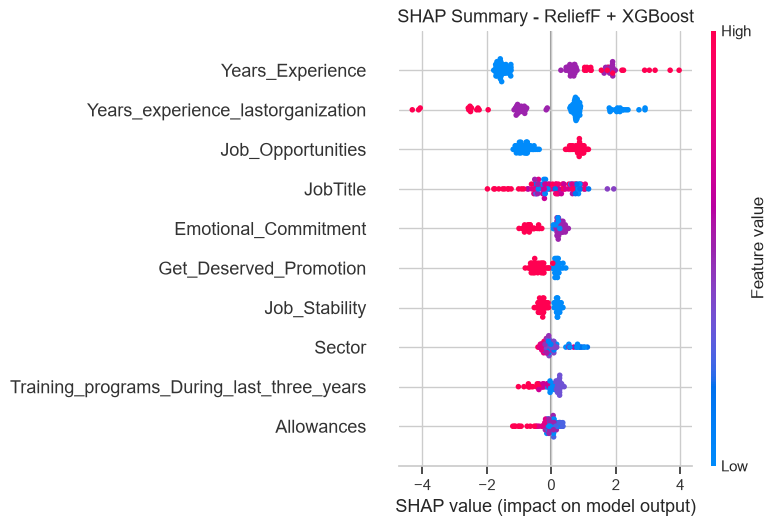

Dependence plots: ['Years_Experience', 'Years_experience_lastorganization', 'Job_Opportunities']


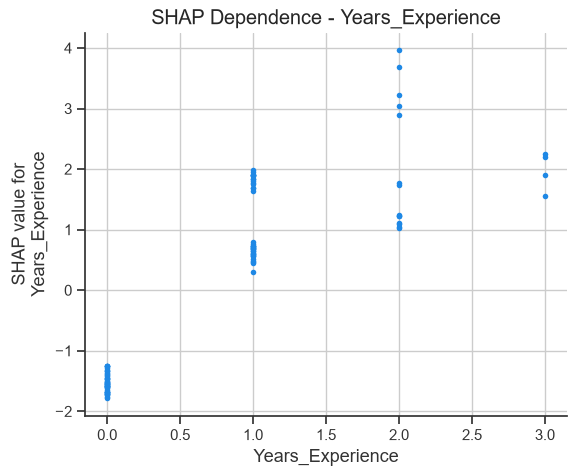

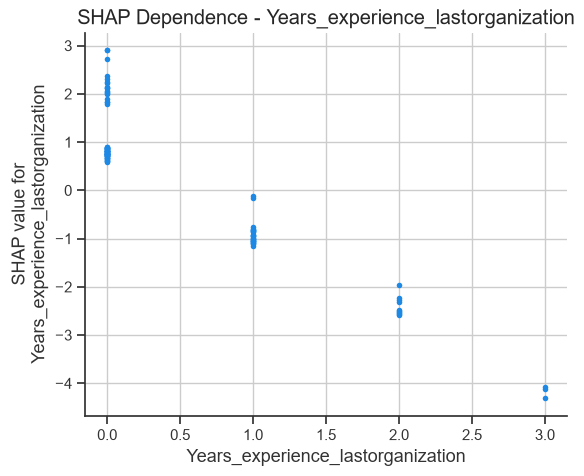

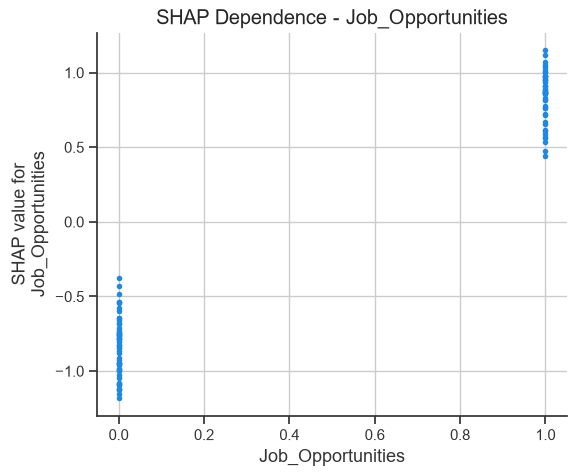

Local explanation: held-out row 919, actual=1, predicted=1, leaver probability=0.7185, SHAP base (raw model score)=0.0072


,Feature,Value,SHAP value
0,Years_experience_lastorganization,0,2.1301
1,Years_Experience,1,1.8408
2,Job_Opportunities,0,-0.9509
3,Training_programs_During_last_three_years,3,-0.7103
4,Job_Stability,1,-0.5287
5,JobTitle,22,-0.5243
6,Emotional_Commitment,1,0.3913
7,Get_Deserved_Promotion,1,-0.3589
8,Allowances,1,0.3041
9,Job_Satisfaction,1,-0.1976


,Feature,SMOTE endpoint effect,No-SMOTE endpoint effect,Direction agrees
0,Years_Experience,0.5217,0.5361,True
1,Years_experience_lastorganization,-0.2798,-0.2738,True


Endpoint effects are sensitivity checks, not causal or cultural effects.


In [24]:
import os
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt
from sklearn.base import clone

shap_selector_name = "ReliefF"
shap_model_name = "XGBoost"
shap_value_scale = "raw model score"
shap_key = (shap_selector_name, shap_model_name)
print("="*60)
print(f"SHAP ANALYSIS - {shap_selector_name} + {shap_model_name} - Saudi")
print("="*60)

if "final_models" not in globals() or shap_key not in final_models:
    raise RuntimeError("Run the final holdout-evaluation cell before this SHAP cell.")
final_pipeline, shap_features = final_models[shap_key]
assert len(shap_features) == best_feature_counts[shap_selector_name][shap_model_name]

shap_smoke = os.environ.get("ATTRITION_SHAP_SMOKE", "0") == "1"
background_size = 10 if shap_smoke else 100
explanation_size = 5 if shap_smoke else 100
X_shap_test = X_test_raw_model.loc[:, shap_features].iloc[:explanation_size].copy()

def tree_input(raw_frame):
    encoded = final_pipeline.named_steps["target_encode"].transform(raw_frame.loc[:, shap_features])
    scaled = final_pipeline.named_steps["scale"].transform(encoded)
    return pd.DataFrame(scaled, index=raw_frame.index, columns=shap_features)

X_shap_tree = tree_input(X_shap_test)
tree_model = final_pipeline.named_steps["clf"]
explainer = shap.TreeExplainer(
    tree_model,
    feature_perturbation="tree_path_dependent",
    model_output="raw",
)
explanation = explainer(X_shap_tree, check_additivity=False)
shap_values = np.asarray(explanation.values)
if shap_values.ndim == 3:
    shap_values = shap_values[:, :, -1]
local_base_value = float(np.asarray(explanation.base_values).reshape(-1)[0])

# Global importance summary.
shap.summary_plot(
    shap_values,
    X_shap_test,
    feature_names=shap_features,
    max_display=10,
    show=False,
)
plt.title(f"SHAP Summary - {shap_selector_name} + {shap_model_name}", fontsize=13)
plt.tight_layout()
plt.show()

mean_abs_shap = pd.Series(np.abs(shap_values).mean(axis=0), index=shap_features).sort_values(ascending=False)
seniority_candidates = ['Age', 'Years_Experience', 'Years_experience_lastorganization']
dependence_features = [f for f in seniority_candidates if f in shap_features]
dependence_features += [f for f in mean_abs_shap.index if f not in dependence_features]
dependence_features = dependence_features[:3]
print("Dependence plots:", dependence_features)
for feature in dependence_features:
    shap.dependence_plot(
        feature,
        shap_values,
        X_shap_test,
        feature_names=shap_features,
        interaction_index=None,
        show=False,
    )
    plt.title(f"SHAP Dependence - {feature}")
    plt.tight_layout()
    plt.show()

# A fixed local case is used instead of selecting a favourable observation.
local_index = 0
local_row_label = X_shap_test.index[local_index]
local_feature_order = np.argsort(np.abs(shap_values[local_index]))[::-1][:10]
local_prediction = final_pipeline.predict_proba(X_shap_test.iloc[[local_index]])[0, 1]
local_class = int(final_pipeline.predict(X_shap_test.iloc[[local_index]])[0])
local_actual = int(y_test.loc[local_row_label])
local_explanation = pd.DataFrame({
    "Feature": [shap_features[i] for i in local_feature_order],
    "Value": [X_shap_test.iloc[local_index, i] for i in local_feature_order],
    "SHAP value": [shap_values[local_index, i] for i in local_feature_order],
})
print(
    f"Local explanation: held-out row {local_row_label}, actual={local_actual}, "
    f"predicted={local_class}, leaver probability={local_prediction:.4f}, "
    f"SHAP base ({shap_value_scale})={local_base_value:.4f}"
)
display(local_explanation.round(4))

# Sensitivity check: same classifier settings and features, changing SMOTE only.
seniority_features = [feature for feature in seniority_candidates if feature in shap_features]
if seniority_features:
    no_smote_pipeline = build_model_pipeline(clone(base_model_templates[shap_model_name]), use_smote=False)
    no_smote_pipeline.fit(X_train_raw_model.loc[:, shap_features], y_train)
    artifact_rows = []
    for feature in seniority_features:
        low_value, high_value = X_train_raw_model[feature].quantile([0.10, 0.90])
        low_frame = X_shap_test.copy()
        high_frame = X_shap_test.copy()
        low_frame[feature] = low_value
        high_frame[feature] = high_value
        smote_effect = np.mean(
            final_pipeline.predict_proba(high_frame)[:, 1]
            - final_pipeline.predict_proba(low_frame)[:, 1]
        )
        no_smote_effect = np.mean(
            no_smote_pipeline.predict_proba(high_frame)[:, 1]
            - no_smote_pipeline.predict_proba(low_frame)[:, 1]
        )
        artifact_rows.append({
            "Feature": feature,
            "SMOTE endpoint effect": smote_effect,
            "No-SMOTE endpoint effect": no_smote_effect,
            "Direction agrees": np.sign(smote_effect) == np.sign(no_smote_effect),
        })
    seniority_check = pd.DataFrame(artifact_rows)
    display(seniority_check.round(4))
    print("Endpoint effects are sensitivity checks, not causal or cultural effects.")
else:
    print("No predefined seniority feature is present in this selected subset.")


## SMOTE vs No-SMOTE Model Comparison
